<div style="background-color:#e3f0f5; padding:20px; border-radius:10px; border-left:8px solid #097a6d;">

<h2 style="margin-top:0; color:#144b71;"><b>Machine Learning I · Group Project</b></h2>
<h4 style="margin-top:-5px; color:#097a6d;">LCD &nbsp;—&nbsp; 2026/2027 &nbsp;—&nbsp; Data Avionaries · <i>Data with Airpose</i></h4>
<br>

<h1 style="margin-bottom:0; color:#0c2e4c;"><b>"The Guild of Gentle Landings"</b></h1>
<h3 style="margin-top:5px; color:#097a6d;"><b>NB0 · Exploratory Data Analysis</b></h3>
<br>

<h3 style="color:#144b71;"><b>Group 17 - Team Members</b></h3>

<table style="color:#0c2e4c;">
<thead>
<tr>
<th style="color:#097a6d; text-align:left;">Name</th>
<th style="color:#097a6d; text-align:left;">Student Number</th>
</tr>
</thead>
<tbody>
<tr>
<td>Mariana Monteiro</td>
<td>20251290</td>
</tr>
<tr>
<td>Martim Carmo</td>
<td>20251305</td>
</tr>
<tr>
<td>Martim Violante</td>
<td>20251310</td>
</tr>
<tr>
<td>Mateus Rodrigues</td>
<td>20251318</td>
</tr>
<tr>
<td>Rafael Portela</td>
<td>20213561</td>
</tr>
</tbody>
</table>

<br>
</div>

<a id="toc"></a>
<div style="background-color:#e3f0f5; padding:15px; border-radius:10px; border-left:6px solid #097a6d; color:#0c2e4c;">

**Table of Contents**

**<a href="#sec-1" style="color:#0c2e4c; text-decoration:none;">1. Business Understanding & Setup</a>**

**<a href="#sec-2" style="color:#0c2e4c; text-decoration:none;">2. First Look at the Data</a>**

**<a href="#sec-3" style="color:#0c2e4c; text-decoration:none;">3. The Target</a>**

**<a href="#sec-4" style="color:#0c2e4c; text-decoration:none;">4. Data Quality</a>**
<ul style="margin-top:-10px; list-style-type:none; padding-left:15px;">
  <li><a href="#sec-4-1" style="color:#097a6d; text-decoration:none;">4.1. Missing Values</a></li>
  <li><a href="#sec-4-2" style="color:#097a6d; text-decoration:none;">4.2. Constant Columns and Duplicates</a></li>
</ul>

**<a href="#sec-5" style="color:#0c2e4c; text-decoration:none;">5. Numerical Features</a>**
<ul style="margin-top:-10px; list-style-type:none; padding-left:15px;">
  <li><a href="#sec-5-1" style="color:#097a6d; text-decoration:none;">5.1. Temperature and Dew Point</a></li>
  <li><a href="#sec-5-2" style="color:#097a6d; text-decoration:none;">5.2. Altimeter</a></li>
  <li><a href="#sec-5-3" style="color:#097a6d; text-decoration:none;">5.3. Engine Power: Horsepower or Pounds of Thrust?</a></li>
  <li><a href="#sec-5-4" style="color:#097a6d; text-decoration:none;">5.4. Wind and Gusts</a></li>
  <li><a href="#sec-5-5" style="color:#097a6d; text-decoration:none;">5.5. Visibility and Cloud Ceiling</a></li>
  <li><a href="#sec-5-6" style="color:#097a6d; text-decoration:none;">5.6. Distance to the Airport and Airport Elevation</a></li>
  <li><a href="#sec-5-7" style="color:#097a6d; text-decoration:none;">5.7. Aircraft Year, Seats and Number of Engines</a></li>
  <li><a href="#sec-5-8" style="color:#097a6d; text-decoration:none;">5.8. Pilot Age</a></li>
  <li><a href="#sec-5-9" style="color:#097a6d; text-decoration:none;">5.9. Hour of the Accident</a></li>
</ul>

**<a href="#sec-6" style="color:#0c2e4c; text-decoration:none;">6. Categorical Features</a>**
<ul style="margin-top:-10px; list-style-type:none; padding-left:15px;">
  <li><a href="#sec-6-1" style="color:#097a6d; text-decoration:none;">6.1. Aircraft Manufacturer</a></li>
</ul>

**<a href="#sec-7" style="color:#0c2e4c; text-decoration:none;">7. Relations with the Target</a>**
<ul style="margin-top:-10px; list-style-type:none; padding-left:15px;">
  <li><a href="#sec-7-1" style="color:#097a6d; text-decoration:none;">7.1. Categorical Features: Fatal Rate per Category</a></li>
  <li><a href="#sec-7-2" style="color:#097a6d; text-decoration:none;">7.2. Numerical Features by Target</a></li>
</ul>

**<a href="#sec-8" style="color:#0c2e4c; text-decoration:none;">8. Relations between Features</a>**

**<a href="#sec-9" style="color:#0c2e4c; text-decoration:none;">9. Summary: Findings and Decisions for NB1</a>**

</div>

In [9]:
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import scipy.stats as stats

# versions of the libraries
print("python", sys.version.split()[0])
print("numpy", np.__version__)
print("pandas", pd.__version__)
print("matplotlib", matplotlib.__version__)
print("seaborn", sns.__version__)
print("scipy", scipy.__version__)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

python 3.12.7
numpy 2.5.3
pandas 3.0.6
matplotlib 3.11.2
seaborn 0.13.2
scipy 1.18.1


<a id="sec-1"></a>
<div style="background-color:#097a6d; padding:20px; border-radius:10px; border-left:8px solid #061b2e;">
  <h3 style="margin:0; color:#FFFFFF;"><b>1. Introduction</b></h3>
  <p style="margin:6px 0 0 0; text-align:right;"><a href="#toc" style="color:#FFFFFF; text-decoration:none; font-size:12px;">&#8593; Back to Table of Contents</a></p>
</div>

The purpose of this notebook is to conduct an exploratory data analysis (EDA) of the dataset provided by the Guild of Gentle Landings. This step aims to develop a comprehensive understanding of the available data, its structure and quality, and the relationships among variables that may influence whether an aviation accident is fatal.


<a id="sec-1-1"></a>
<div style="background-color:#e3f0f5; padding:20px; border-radius:10px; border-left:8px solid #097a6d; color:#097a6d;">
  <b>1.1. Project Context</b>
</div>



The dataset contains records of past aviation accidents, describing when and where each accident happened, the weather conditions, the aircraft, the pilot and the flight. Each record represents a unique accident, classified as either:

**1 (fatal)** - at least one person died in the accident;

**0 (not fatal)** - nobody died, even if there were injuries or damage.

The Guild needs to know, **one hour after an accident**, whether it is likely to have been fatal, so that support and investigation resources are sent where they are needed the most. Through this analysis, we aim to uncover the patterns and conditions that distinguish these two classes and to build a foundation for a predictive model, evaluated with the F1 score of the fatal class, that uses only the information available at that moment.


<a id="sec-1-1"></a>
<div style="background-color:#e3f0f5; padding:20px; border-radius:10px; border-left:8px solid #097a6d; color:#097a6d;">
  <b>1.1. Project Goal</b>
</div>

The exploratory data analysis (EDA) aims to:

- **Assess data quality and completeness**, including missing values, duplicates, data types and inconsistent spellings.
- **Explore distributions** of numerical and categorical features to understand their behaviour and identify outliers and impossible values.
- **Analyze relationships** between predictors and the target variable `fatal`, as well as among the predictors themselves.
- **Identify key insights and decisions** that will guide data preparation, feature engineering and model development in NB1.

As required, this notebook does not modify the data and does not train any model.

## Import Datasets

In [10]:
learn = pd.read_csv("learn.csv")
predict = pd.read_csv("predict.csv")

print(f"learn:   {learn.shape[0]:,} rows x {learn.shape[1]} columns")
print(f"predict: {predict.shape[0]:,} rows x {predict.shape[1]} columns")
learn.head()

learn:   16,979 rows x 42 columns
predict: 4,245 rows x 41 columns


,row_id,ev_year,ev_month,ev_country,ev_dow,ev_hour,light_cond,wx_cond_basic,sky_cond_ceil,sky_cond_nonceil,gust_ind,sky_ceil_ht,vis_sm,wx_temp,wx_temp_c,wx_dew_pt,wind_dir_deg,wind_vel_kts,gust_kts,altimeter,apt_dist,apt_elev,far_part,acft_category,homebuilt,fixed_retractable,type_fly,flt_plan_filed,second_pilot,acft_make,ifr_equipped_cert,num_eng,total_seats,acft_year,eng_type,carb_fuel_injection,eng_power,pilot_age,pilot_sex,pilot_med_certf,phase,fatal
0,A00001,2018,9,USA,Th,19.0,DAYL,VMC,NONE,CLER,T,0,10.0,59,15.0,49,38,7.0,0,30.06,0,NaN,091,air,N,FIXD,PERS,NONE,N,PIPER,0,1.0,2.0,1956.0,REC,CARB,NaN,71.0,M,CL3,Landing,0
1,A00002,2011,7,USA,Sa,17.0,DAYL,VMC,NONE,CLER,T,0,5.0,70,21.1,56,0,3.0,0,29.91,9,629.0,091,AIR,n,FIXD,INST,NONE,n,AMERICAN AVIATION,0,1.0,2.0,NaN,REC,CARB,108.0,17.0,M,CL1,Maneuvering,1
2,A00004,2013,7,USA,Su,22.0,DAYL,VMC,UNK,FEW,F,0,10.0,80,26.7,73,0,10.0,17,30.06,0,NaN,091,AIR,N,FIXD,PERS,UNK,N,LUSCOMBE,0,1.0,2.0,NaN,REC,CARB,84.0,46.0,M,CL3,Landing,0
3,A00005,2019,9,USA,Fr,0.0,DAYL,VMC,BKN,NaN,T,10208,10.0,80,26.7,33,261,6.0,0,30.07,0,NaN,091,air,n,FIXD,PERS,NONE,N,AMERICAN AVIATION,1,1.0,4.0,1976.0,REC,CARB,150.0,31.0,M,CL1,Enroute,1
4,A00006,2008,4,USA,Su,1.0,DAYL,VMC,NONE,CLER,F,0,10.0,62,16.7,36,261,13.0,18,29.90,0,3092.0,091,AIR,N,FIXD,PERS,NONE,n,CESSNA,0,1.0,4.0,NaN,REC,CARB,174.0,68.0,M,CL3,Approach,0


In [11]:
learn.info()

<class 'pandas.DataFrame'>
RangeIndex: 16979 entries, 0 to 16978
Data columns (total 42 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   row_id               16979 non-null  str    
 1   ev_year              16979 non-null  int64  
 2   ev_month             16979 non-null  int64  
 3   ev_country           16979 non-null  str    
 4   ev_dow               16979 non-null  str    
 5   ev_hour              16960 non-null  float64
 6   light_cond           16953 non-null  str    
 7   wx_cond_basic        16960 non-null  str    
 8   sky_cond_ceil        14977 non-null  str    
 9   sky_cond_nonceil     14158 non-null  str    
 10  gust_ind             16979 non-null  str    
 11  sky_ceil_ht          16979 non-null  int64  
 12  vis_sm               16258 non-null  float64
 13  wx_temp              16979 non-null  int64  
 14  wx_temp_c            16979 non-null  float64
 15  wx_dew_pt            16979 non-null  int64  
 1

## Numerical and Categorical Columns

In [12]:
num_cols = learn.drop(columns=["row_id", "fatal"]).select_dtypes(include="number").columns.tolist()
cat_cols = learn.drop(columns=["row_id", "fatal"]).select_dtypes(exclude="number").columns.tolist()

print(f"{len(num_cols)} numerical:  ", num_cols)
print(f"{len(cat_cols)} categorical:", cat_cols)

20 numerical:   ['ev_year', 'ev_month', 'ev_hour', 'sky_ceil_ht', 'vis_sm', 'wx_temp', 'wx_temp_c', 'wx_dew_pt', 'wind_dir_deg', 'wind_vel_kts', 'gust_kts', 'altimeter', 'apt_dist', 'apt_elev', 'ifr_equipped_cert', 'num_eng', 'total_seats', 'acft_year', 'eng_power', 'pilot_age']
20 categorical: ['ev_country', 'ev_dow', 'light_cond', 'wx_cond_basic', 'sky_cond_ceil', 'sky_cond_nonceil', 'gust_ind', 'far_part', 'acft_category', 'homebuilt', 'fixed_retractable', 'type_fly', 'flt_plan_filed', 'second_pilot', 'acft_make', 'eng_type', 'carb_fuel_injection', 'pilot_sex', 'pilot_med_certf', 'phase']


40 features: 20 stored as numbers and 20 as text.

## Target

In [21]:
counts = learn["fatal"].value_counts()
print(counts)
print('\nFatal rate:',((counts[1]/counts.sum())*100).round(1),'%')


fatal
0    14090
1     2889
Name: count, dtype: int64

Fatal rate: 17.0 %


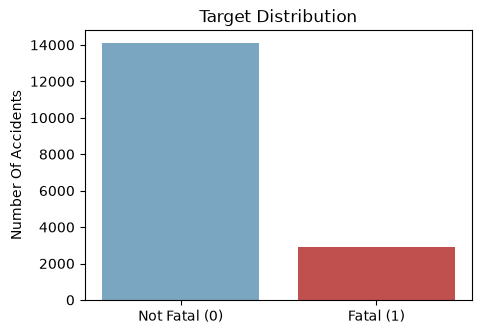

In [22]:
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(["Not Fatal (0)", "Fatal (1)"], counts.sort_index(), color=["#7aa6c2", "#c0504d"])
ax.set_title("Target Distribution")
ax.set_ylabel("Number Of Accidents")
plt.show()

The target variable exhibits a significant class imbalance: out of roughly 17,000 total accidents, around 14,100 (~83%) are Not Fatal (0), while only 2,900 (~17%) are Fatal (1). Because non-fatal cases heavily outnumber fatal ones, a model trained on this raw distribution risks becoming biased toward the majority class